# REDES NEURAIS ARTIFICIAIS

# PARTE 1: Classificação Binária - Diagnóstico de Câncer de Mama

Base de dados: Breast Cancer Wisconsin (Diagnostic) -
https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic

In [ ]:
!pip install --upgrade pip

In [26]:
!pip install numpy pandas matplotlib

  Using cached matplotlib-3.11.2-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (5.2 kB)
Using cached matplotlib-3.11.2-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (11.0 MB)
Using cached contourpy-1.4.0-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (384 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 6.2 MB/s  0:00:00m0:00:0100:01
Using cached kiwisolver-1.5.1-cp314-cp314-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (1.5 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 6.4 MB/s  0:00:01m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]


In [2]:
!pip install scikeras==0.13.0 tensorflow==2.22.0rc0 scikit-learn==1.9.1 keras==3.15.1

  Using cached scikeras-0.13.0-py3-none-any.whl.metadata (3.1 kB)
  Using cached scipy-1.18.1-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (62 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 638.4/638.4 MB 3.3 MB/s  0:01:46m0:00:0100:03
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 6.6 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 6.8 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 6.6 MB/s  0:00:01m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.1/5.1 MB 7.0 MB/s  0:00:00 eta 0:00:01
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 7.0 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 6.3 MB/s  0:00:03

In [9]:
import pandas as pd
import tensorflow as tf
import numpy as np
import sklearn
import scikeras

In [10]:
pd.__version__, tf.__version__, sklearn.__version__, scikeras.__version__

('3.1.1', '2.22.0-rc0', '1.9.1', '0.13.0')

### Carregar os dados

1) Carregue a base de dados, faça a divisição de treino e teste (para isso, utilize a função train_test_split do sklearn), como o tamanho da base de teste de 0.25.

In [11]:
from sklearn.model_selection import train_test_split

X = pd.read_csv('dados_breast.csv')
Y = pd.read_csv('rotulos_breast.csv')

X_treinamento, X_teste, y_treinamento, y_teste = train_test_split(X, Y, test_size=.25)

In [12]:
X_treinamento.shape, y_treinamento.shape

((426, 30), (426, 1))

In [13]:
X_teste.shape, y_teste.shape

((143, 30), (143, 1))

### Estrutura da Rede Neural Artificial e Teste

In [16]:
from scikeras.wrappers import KerasClassifier

from sklearn.model_selection import cross_val_score

import keras
from keras import layers

2) Crie a RNA com as seguintes configurações:

a) uma camada de entrada de com 30 neurônios;

b) uma camada oculta densa com 16 neurônios. Porque a camada oculta tem essa quantidade de neurônios?

c) adicione na camada oculta a função de ativação relu e inicialize os pesos de utilize o Random uniform initializer (https://www.tensorflow.org/api_docs/python/tf/keras/initializers);

d) adicione a camada de saíde com a função de ativação sigmoid. Porque foi utilizada esta função para a saída da RNA?

3) Porque utilizamos a classe chamada Sequential para a RNA?

In [18]:
# https://iaexpert.academy/2020/05/04/quantas-camadas-escondidas-e-quantos-neuronios-incluir-numa-rede-neural-artificial/

def Net() -> keras.Sequential:
  keras.backend.clear_session()

  return keras.Sequential([
      layers.Input(shape=(30,)),
      layers.Dense(16, activation='relu', kernel_initializer=keras.initializers.RandomUniform()),
      layers.Dense(1, activation='sigmoid')
  ])

print()
print(
    'b) A escolha de quantidade de neurônios é empírica, mas segundo recomendação: \n'
    '   O número de neurônios escondidos deve estar entre o tamanho da camada de entrada e o da camada de saída (30 + 1 // 2 = 16)'
)

print()
print(
    'd) A escolha de sigmóide é para o classificador retornar num intervalo (0-1), \n'
    '   utilizando um threshold para classificar (tem cancêr ou não)'
)



b) A escolha de quantidade de neurônios é empírica, mas segundo recomendação: 
   O número de neurônios escondidos deve estar entre o tamanho da camada de entrada e o da camada de saída (30 + 1 // 2 = 16)

d) A escolha de sigmóide é para o classificador retornar num intervalo (0-1), 
   utilizando um threshold para classificar (tem cancêr ou não)


4) A partir da RNA gerada, explique o que são os valores apresentados na tabela da rede_neural.summary()

In [20]:
rede_neural = Net()

print(rede_neural.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 513 (2.00 KB)

 Trainable params: 513 (2.00 KB)

 Non-trainable params: 0 (0.00 B)

None


In [10]:
# total params = 513
# 513 = ( ( 30 (camada de entrada) * 1 + 1 (bias) ) * 16 (camada do meio) ) + ( 16 * 1 + 1 (bias) ) )

5) Adicione um otimizador Adam (https://www.tensorflow.org/api_docs/python/tf/keras/optimizers) e especifique a classe loss binário - binary crossentropy (https://www.tensorflow.org/api_docs/python/tf/keras/losses) e a classe metrics para utilizar a métrica de avaliação de acurácia binária (https://www.tensorflow.org/api_docs/python/tf/keras/metrics)

6) Para que servem os otimizadores? Como o otimizador Adam funciona?

7) Depois de estruturados os parâmtros da RNA, utilize a função .fit para fazer o treinamento da rede. Como foi utilizado o otimizador Adam, e ele é baseado na descida do gradiente estocástica, é possível definir a quantidade de registros que serão enviados para a RNA, isto é, em cada batch serão utilizados 10 registros. Quantos batches serão utilizados ao total?

8) Por fim, defina o número de épocas em que ocorre o treinamento igual a 100.

In [21]:
opt = keras.optimizers.Adam()

# https://machinelearningmastery.com/adam-optimization-algorithm-for-deep-learning/

print()
print(
    '6) Adam é um algoritmo para atualizar os pesos da rede neural (vai em encontro ao gradiente descendente estocástico) \n',
    '   ao invés de um learning rate fixo, o Adam utiliza um learning rate adaptativo por parâmetro, focando o treinamento nos parâmetros mais significativos'
)

print()

rede_neural.compile(optimizer=opt, loss=keras.losses.BinaryCrossentropy(), metrics=[keras.metrics.BinaryAccuracy()])

fit_history_1 = rede_neural.fit(X_treinamento, y_treinamento, batch_size=10, epochs=100)

print()
print(
    '7) 43 = 426 (tamanho do batch - linhas) // 10 (quantidade de registros p/ cada linha)'
)


6) Adam é um algoritmo para atualizar os pesos da rede neural (vai em encontro ao gradiente descendente estocástico) 
    ao invés de um learning rate fixo, o Adam utiliza um learning rate adaptativo por parâmetro, focando o treinamento nos parâmetros mais significativos

Epoch 1/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - binary_accuracy: 0.6901 - loss: 4.4661
Epoch 2/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - binary_accuracy: 0.7441 - loss: 1.3686
Epoch 3/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - binary_accuracy: 0.7676 - loss: 1.1590
Epoch 4/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - binary_accuracy: 0.8498 - loss: 0.5067
Epoch 5/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - binary_accuracy: 0.7887 - loss: 0.9535
Epoch 6/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - binary_accuracy: 0.8427 - loss: 0.6247
Epoch 7/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - binary_accuracy: 0.8920 - loss: 0.3363
Epoch 8/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - binary_accuracy: 0.8803 - los

In [22]:
df_loss_1 = pd.DataFrame(fit_history_1.history['loss'])
display(df_loss_1.describe())

df_acc_1 = pd.DataFrame(fit_history_1.history['binary_accuracy'])
display(df_acc_1.describe())

,0
count,100.000000
mean,0.376647
std,0.456575
min,0.163173
25%,0.221074
50%,0.274491
75%,0.366599
max,4.466107


,0
count,100.000000
mean,0.907394
std,0.041959
min,0.690141
25%,0.896714
50%,0.915493
75%,0.934272
max,0.950704


9) Crie uma variável chamada previsoes para realizar a previsão dos dados de teste (X_teste) O resultado da rede deve ser um valor entre 0 e 1. Porque isso acontece?

In [23]:
print()
print('9) Pois definimos que a função de saída é sigmóide entre 0 e 1 que utiliza um threshold.')


9) Pois definimos que a função de saída é sigmóide entre 0 e 1


10) Converta o resultado que está em probabilidade para valores binários com um limiar (treshold) de 0.5.

In [24]:
previsoes = rede_neural.predict(X_teste)

previsoes = previsoes > 0.5

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


9) Explique o resultado da RNA.

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - binary_accuracy: 0.8462 - loss: 0.6769

9) Acurácia relativamente alta mas não implica num modelo bom necessariamente. 
    Loss bem baixo e, combinado com acurácia alta, não sugere overfitting. Rede está consideravelmente boa para o propósito. 
    Além disso, ao analisar a matriz de confusão, vamos que o modelo esta errando mais em falsos negativos. 
    Em teoria, falsos negativos estar mais alto é essencialmente RUIM: pois indicamos que o paciente NÃO tem quando na verdade ele TEM cancêr.



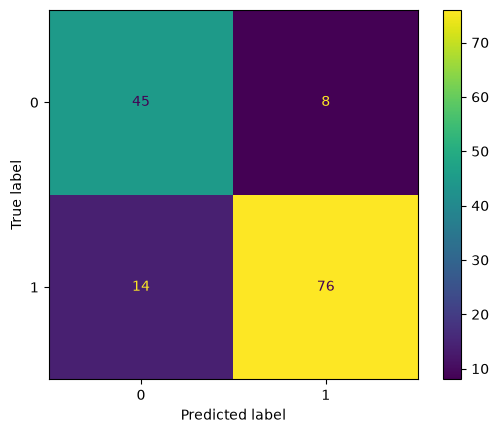

In [27]:
rede_neural.evaluate(X_teste, y_teste)

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

m = ConfusionMatrixDisplay(confusion_matrix(y_teste, previsoes))
m.plot()

print()
print(
    '9) Acurácia relativamente alta mas não implica num modelo bom necessariamente. \n',
    '   Loss bem baixo e, combinado com acurácia alta, não sugere overfitting. Rede está consideravelmente boa para o propósito. \n',
    '   Além disso, ao analisar a matriz de confusão, vamos que o modelo esta errando mais em falsos negativos. \n',
    '   Em teoria, falsos negativos estar mais alto é essencialmente RUIM: pois indicamos que o paciente NÃO tem quando na verdade ele TEM cancêr.'
)

print()

## Camadas e Otimização da RNA



10) Adicione mais uma camada para oculta densa com 16 neurônio com a função de ativação relu e inicialize os pesos de utilize o Random uniform initializer. Qual o total de parâmetros da RNA agora?

In [29]:
def Net() -> keras.Sequential:
  keras.backend.clear_session()

  return keras.Sequential([
      layers.Input(shape=(30,)),
      layers.Dense(16, activation='relu', kernel_initializer=keras.initializers.RandomUniform()),
      layers.Dense(16, activation='relu', kernel_initializer=keras.initializers.RandomUniform()),
      layers.Dense(1, activation='sigmoid')
  ])

In [31]:
rede_neural = Net()

print(rede_neural.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 785 (3.07 KB)

 Trainable params: 785 (3.07 KB)

 Non-trainable params: 0 (0.00 B)

None


In [18]:
# 785 = ( ( 30 + 1 ) * 16) + ( ( 16 + 1 ) * 16) + ( ( 16 + 1 ) * 1 )

11) Abaixo são adicionados os parâmetros do otimizador, que são a taxa de aprendizado e o clipvalue. O que eles fazem?

In [32]:
otimizador = tf.keras.optimizers.Adam(learning_rate = 0.001, clipvalue = 0.5)
rede_neural.compile(optimizer = otimizador, loss = 'binary_crossentropy', metrics = ['binary_accuracy'])

print()
print(
    'Assim como qualquer outro otimizador, o Adam serve para ajustar os pesos e parâmetros do modelo para mininizar o erro. \n'

    'O learning rate é a taxa de aprendizado. Define o passo que o otimizador vai tomar para aplicar o ajuste. Geralmente \n'
    'se trabalha com passos pequenos (diminuir o erro ao máximo), mas não tão pequenos (vanishing gradient problem). \n'

    'Já o clip value é um mecanismo de segurança contra um learning rate grande o suficiente que é capaz de... não aprender; \n'
    'Quando o learning rate é muito alto, o modelo acaba desprezando o aprendizado anterior (o passo se torna muito grande). \n'
    'Qualquer learning rate que seja maior que .5, é "clipado".'
)


Assim como qualquer outro otimizador, o Adam serve para ajustar os pesos e parâmetros do modelo para mininizar o erro. 
O learning rate é a taxa de aprendizado. Define o passo que o otimizador vai tomar para aplicar o ajuste. Geralmente 
se trabalha com passos pequenos (diminuir o erro ao máximo), mas não tão pequenos (vanishing gradient problem). 
Já o clip value é um mecanismo de segurança contra um learning rate grande o suficiente que é capaz de... não aprender; 
Quando o learning rate é muito alto, o modelo acaba desprezando o aprendizado anterior (o passo se torna muito grande). 
Qualquer learning rate que seja maior que .5, é "clipado".


12) Teste novamente a RNA. Aumentar a quantidade de camadas melhorou ou piorou os resultados? Explique o que aconteceu com a RNA e porque.

In [ ]:
fit_history_2 = rede_neural.fit(X_treinamento, y_treinamento, batch_size = 10, epochs = 100)

In [34]:
print('Resultados anteriores:')

display(df_loss_1.describe())
display(df_acc_1.describe())

print('Resultados novos:')

df_loss_2 = pd.DataFrame(fit_history_2.history['loss'])
display(df_loss_2.describe())

df_acc_2 = pd.DataFrame(fit_history_2.history['binary_accuracy'])
display(df_acc_2.describe())

Resultados anteriores:


,0
count,100.000000
mean,0.376647
std,0.456575
min,0.163173
25%,0.221074
50%,0.274491
75%,0.366599
max,4.466107


,0
count,100.000000
mean,0.907394
std,0.041959
min,0.690141
25%,0.896714
50%,0.915493
75%,0.934272
max,0.950704


Resultados novos:


,0
count,100.000000
mean,0.425201
std,0.110051
min,0.264156
25%,0.349579
50%,0.394423
75%,0.471622
max,0.883201


,0
count,100.000000
mean,0.866315
std,0.040167
min,0.605634
25%,0.859155
50%,0.875587
75%,0.887324
max,0.920188


In [35]:
previsoes = rede_neural.predict(X_teste)

previsoes = previsoes > 0.5

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - binary_accuracy: 0.7692 - loss: 0.7223  

12) No resultado superficial, a rede parece ter piorado. Mas, 
     ao analisar a matriz de confusão vemos que a rede está errando mais em falsos negativos 
     o que é essencialmente ruim (analisar resposta anterior). 
     Ao adicionar mais camadas permitimos que a rede aprenda padrões mais complexos, mas isso ser bom ou não 
     depende do nosso conjunto de dados (é necessário, ou não?). 
     Não sugere necessariamente overfitting, pois vemos que no próprio treinamento os ajustes não melhoraram a rede. 
     Isso pode sugerir que nossa inicialização da rede random pode ser ruim ao usar 2 camadas ocultas.



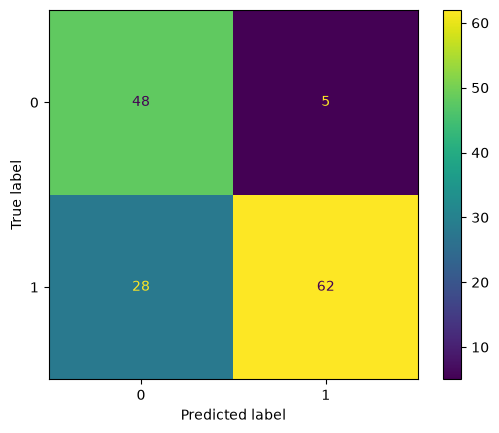

In [36]:
rede_neural.evaluate(X_teste, y_teste)

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

m = ConfusionMatrixDisplay(confusion_matrix(y_teste, previsoes))
m.plot()

print()
print(
    '12) No resultado superficial, a rede parece ter piorado. Mas, \n',
    '    ao analisar a matriz de confusão vemos que a rede está errando mais em falsos negativos \n',
    '    o que é essencialmente ruim (analisar resposta anterior). \n',
    '    Ao adicionar mais camadas permitimos que a rede aprenda padrões mais complexos, mas isso ser bom ou não \n',
    '    depende do nosso conjunto de dados (é necessário, ou não?). \n',
    '    Não sugere necessariamente overfitting, pois vemos que no próprio treinamento os ajustes não melhoraram a rede. \n',
    '    Isso pode sugerir que nossa inicialização da rede random pode ser ruim ao usar 2 camadas ocultas.',
)

print()

## K-Fold Cross Validation

13) Assista o vídeo https://youtu.be/RczbeFs_WbQ?si=f1Yu4LZaGDfZZpbZ para compreender melhor sobre como funciona o k-fold cross validation. Explique como esta rede foi configurada e como é possível chegar no resultado dela. O que é necessário fazer?


14) Calcule também o Desvio Padrão dos resultados para avaliar o modelo. O que é possível concluir com esse resultado?



In [37]:
from scikeras.wrappers import KerasClassifier
from sklearn.model_selection import cross_val_score, cross_validate, cross_val_predict
from keras.models import Sequential
from keras import backend as k

In [38]:
def analisar_estimator(k, resultados):
    melhor_modelo = resultados['estimator'][k]

    y_pred = melhor_modelo.predict(X_teste)

    from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

    m = ConfusionMatrixDisplay(confusion_matrix(y_teste, y_pred))
    m.plot()

In [39]:
def criar_rede():
  k.clear_session()
  rede_neural = Sequential([
      tf.keras.layers.InputLayer(shape=(30,)),
      tf.keras.layers.Dense(units=16, activation='relu', kernel_initializer='random_uniform'),
      tf.keras.layers.Dense(units=16, activation='relu', kernel_initializer='random_uniform'),
      tf.keras.layers.Dense(units=1, activation = 'sigmoid')])
  otimizador = tf.keras.optimizers.Adam(learning_rate = 0.001, clipvalue = 0.5)
  rede_neural.compile(optimizer = otimizador, loss = 'binary_crossentropy', metrics = ['binary_accuracy'])
  return rede_neural

In [ ]:
rede = KerasClassifier(model = criar_rede, epochs = 100, batch_size = 10)
resultados_completos = cross_validate(estimator = rede, X = X, y = Y, cv = 10, scoring = 'accuracy', return_estimator=True, return_indices=True)

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


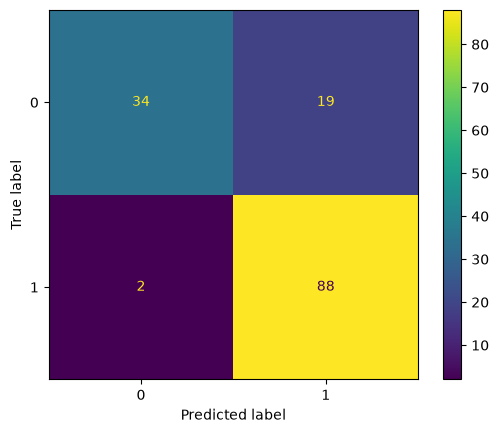

In [44]:
analisar_estimator(k = np.argmax(resultados_completos['test_score']), resultados = resultados_completos)

In [46]:
print()
print(
    '13) A rede aqui é exatamente a mesma do experimento anterior. \n',
    '    O que muda essencialmente é como treinamentos a rede. O K-fold cross validation permite separar \n',
    '    a rede múltiplas vezes entre conjunto de teste e treinamento, Ou seja, não nos limitamos em uma única separação \n',
    '    e isso permite atingir resultados essencialmente melhores, já que a rede se adapta melhor ao que ela ainda não viu. \n',

    '    Podemos ver que quantidade de FNs diminui no novo medelo e os FPs aumentaram.'
)

print()
print(
    '14) O desvio padrão baixo sugere que o modelo não teve muita discrepância nos conjuntos de teste/treinamento utilizados \n',
    '    o que é bom pois sugere que o modelo é estável e não depende muito da separação entre teste/treinamento.'
)

df_resultados = pd.DataFrame(resultados_completos['test_score'])
display(df_resultados.describe())


13) A rede aqui é exatamente a mesma do experimento anterior. 
     O que muda essencialmente é como treinamentos a rede. O K-fold cross validation permite separar 
     a rede múltiplas vezes entre conjunto de teste e treinamento, Ou seja, não nos limitamos em uma única separação 
     e isso permite atingir resultados essencialmente melhores, já que a rede se adapta melhor ao que ela ainda não viu. 
     Podemos ver que quantidade de FPs diminui no novo medelo.

14) O desvio padrão baixo sugere que o modelo não teve muita discrepância nos conjuntos de teste/treinamento utilizados 
     o que é bom pois sugere que o modelo é estável e não depende muito da separação entre teste/treinamento.


,0
count,10.000000
mean,0.806579
std,0.068087
min,0.701754
25%,0.758772
50%,0.798246
75%,0.850877
max,0.929825


## Overfitting e Dropout

14) Como vimos, o modelo anterior sofreu overfitting. Para reduzir esse problema, aplicamos a técnica de regularização conhecida como dropout (artigo oficial: https://www.cs.toronto.edu/~rsalakhu/papers/srivastava14a.pdf e explicação em português: https://www.deeplearningbook.com.br/como-funciona-o-dropout/ ). Aplique o dropout de 20% na primeira e segunda camada oculta. O que acontece com os resultados? E o Desvio Padrão?

In [47]:
def dropout_net():
  k.clear_session()
  rede_neural = Sequential([
      tf.keras.layers.InputLayer(shape=(30,)),
      tf.keras.layers.Dense(units=16, activation='relu', kernel_initializer='random_uniform'),
      tf.keras.layers.Dropout(rate = .2),
      tf.keras.layers.Dense(units=16, activation='relu', kernel_initializer='random_uniform'),
      tf.keras.layers.Dropout(rate = .2),
      tf.keras.layers.Dense(units=1, activation = 'sigmoid')])
  otimizador = tf.keras.optimizers.Adam(learning_rate = 0.001, clipvalue = 0.5)
  rede_neural.compile(optimizer = otimizador, loss = 'binary_crossentropy', metrics = ['binary_accuracy'])
  return rede_neural

In [ ]:
rede_dropout = KerasClassifier(model = dropout_net, epochs = 100, batch_size = 10)
resultados_dropout_completo = cross_validate(estimator = rede_dropout, X = X, y = Y, cv = 10, scoring = 'accuracy', return_estimator=True, return_indices=True)

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


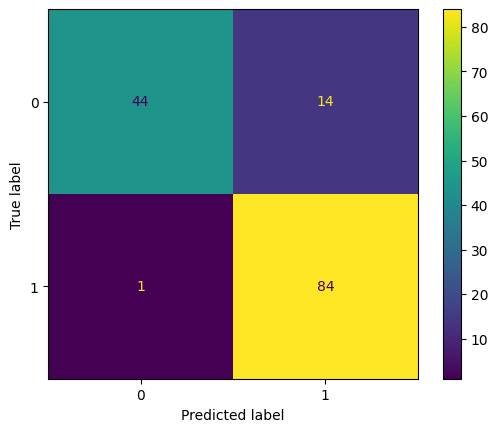

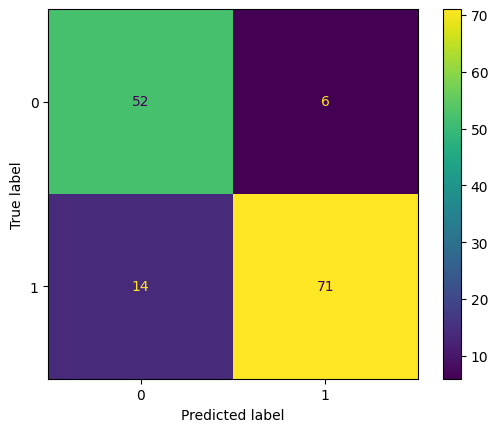

In [83]:
analisar_estimator(k = np.argmax(resultados_dropout_completo['test_score']), resultados = resultados_completos_dropout)

In [45]:
df_resultados_dropout = pd.DataFrame(resultados_dropout)
display(df_resultados_dropout.describe())

print()
print(
    '14) Resultados se mantiveram parecidos, mas a quantidade de FPs diminui de 2 para 1'
)

Min:  0.8245614035087719
Max:  0.9107142857142857


,0
count,10.000000
mean,0.870019
std,0.027416
min,0.824561
25%,0.846491
50%,0.877193
75%,0.890351
max,0.910714



14)


## Tuning dos Hiperparâmetros (técnicas de ajuste)

Hyperparameter Tuning (Ajuste de Hiperparâmetros) é o processo geral de encontrar os melhores valores para os hiperparâmetros de um modelo de machine learning.
Exemplos de hiperparâmetros:

- Taxa de aprendizado (learning rate)

- Número de árvores em um RandomForest

- Número de camadas ou neurônios em uma rede neural

- Tipo de kernel em um SVM

O tuning pode ser feito por diferentes técnicas, como:

- Grid Search

- Random Search

- Bayesian Optimization, etc.

15) Descreva como a RNA foi configurada para fazer o processo de tuning.

In [57]:
def criar_rede(optimizer, loss, kernel_initializer, activation, neurons):
  k.clear_session()
  rede_neural = Sequential([
      tf.keras.layers.InputLayer(shape=(30,)),
      tf.keras.layers.Dense(units=neurons, activation=activation, kernel_initializer=kernel_initializer),
      tf.keras.layers.Dropout(rate = 0.2),
      tf.keras.layers.Dense(units=neurons, activation=activation, kernel_initializer=kernel_initializer),
      tf.keras.layers.Dropout(rate = 0.2),
      tf.keras.layers.Dense(units=1, activation = 'sigmoid')])
  rede_neural.compile(optimizer = optimizer, loss = loss, metrics = ['binary_accuracy'])
  return rede_neural

In [58]:
rede_neural = KerasClassifier(model = criar_rede)

In [69]:
parametros = {
    'batch_size': [10, 30],
    'epochs': [50],
    'model__optimizer': ['adam', 'sgd'],
    'model__loss': ['binary_crossentropy', 'hinge'],
    'model__kernel_initializer': ['random_uniform', 'normal'],
    'model__activation': ['relu', 'tanh'],
    'model__neurons': [16, 8]
}

In [62]:
# caso tiver problema com a configuração anterior, testar essa

# parametros = {
#     'batch_size': [10, 30],
#     'epochs': [50],
#     'model__optimizer': ['adam'],
#     'model__loss': ['binary_crossentropy'],
#     'model__kernel_initializer': ['random_uniform', 'normal'],
#     'model__activation': ['relu'],
#     'model__neurons': [16]
# }

In [70]:
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    estimator = rede_neural,
    param_grid = parametros,
    scoring = 'accuracy',
    cv = 5
)

In [ ]:
grid_search = grid_search.fit(X, Y)

In [74]:
print(grid_search)

GridSearchCV(cv=5,
             estimator=KerasClassifier(model=<function criar_rede at 0x75c3f6d4eae0>),
             param_grid={'batch_size': [10, 30], 'epochs': [50],
                         'model__activation': ['relu', 'tanh'],
                         'model__kernel_initializer': ['random_uniform',
                                                       'normal'],
                         'model__loss': ['binary_crossentropy', 'hinge'],
                         'model__neurons': [16, 8],
                         'model__optimizer': ['adam', 'sgd']},
             scoring='accuracy')


In [75]:
melhores_parametros = grid_search.best_params_
print(melhores_parametros)

{'batch_size': 10, 'epochs': 50, 'model__activation': 'relu', 'model__kernel_initializer': 'random_uniform', 'model__loss': 'binary_crossentropy', 'model__neurons': 8, 'model__optimizer': 'adam'}


In [76]:
melhor_precisao = grid_search.best_score_
print(melhor_precisao)

0.8981524607980127


5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step


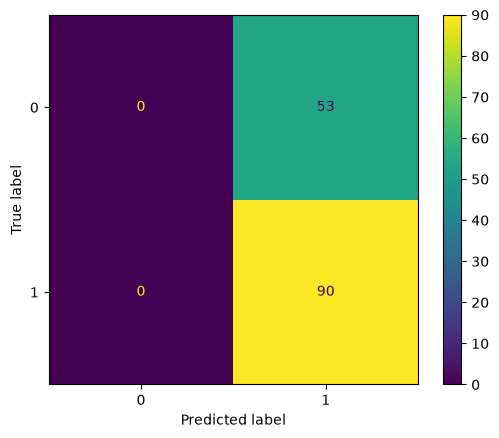

In [77]:
melhor_modelo = criar_rede(
    optimizer = melhores_parametros['model__optimizer'],
    loss = melhores_parametros['model__loss'],
    kernel_initializer = melhores_parametros['model__kernel_initializer'],
    activation = melhores_parametros['model__activation'],
    neurons = melhores_parametros['model__neurons']
)

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred = melhor_modelo.predict(X_teste)
y_pred = (y_pred > 0.5)

m = ConfusionMatrixDisplay(confusion_matrix(y_teste, y_pred))
m.plot()

16) É possível melhorar ainda mais a curácia da RNA? Como?

#Para salvar o seu modelo de RNA

In [ ]:
classificador = KerasClassifier(model = criar_rede, epochs = 100, batch_size = 10)
classificador.save('classificador_breast.keras')

In [ ]:
classificador_novo = tf.keras.models.load_model('/content/classificador_breast.keras')

In [ ]:
classificador_novo.summary()